# Galaxy10: diez ejemplos por tratamiento
## Gaussian, CLAHE, Otsu, split and merge, Qwen y MLflow

**Muestra didáctica:** las mismas **10 galaxias de validación**, una por clase, reciben los **7 tratamientos**. Se generan **70 imágenes procesadas**. La selección es determinista: primera aparición de cada clase en `validacion_1000.csv`, sin seleccionar por éxito de predicción.

**Experimento completo:** 1,000 imágenes por tratamiento, 7,000 clasificaciones. Sus resultados y predicciones se incluyen para consulta. Las métricas de esta muestra de diez imágenes se muestran por separado.

Este notebook sustituye la demo anterior de tres ejemplos. Incluye el algoritmo de `segmentacion.py`, el preprocesamiento y la interfaz de clasificación de `evaluar_qwen.py`, y una exportación equivalente a la de `experimentar_split_merge.py`, limitada a la muestra.

**Uso:** subir el `.ipynb` a Google Colab y ejecutar las celdas en orden. El recorrido predeterminado usa CPU, ejecuta realmente los siete tratamientos y consulta las predicciones de Qwen previamente calculadas. Las celdas opcionales permiten ejecutar Qwen y registrar una nueva demo en MLflow. No se necesita cargar el HDF5 ni descargar pesos para el recorrido predeterminado.

## 1. Dependencias
Ejecutar antes de grabar. La instalación necesita internet en Colab. Qwen y MLflow se instalan únicamente si se activan sus secciones opcionales.

In [ ]:
%pip -q install opencv-python-headless pillow matplotlib pandas scikit-learn

In [1]:
import base64, hashlib, io, json, re, time, zipfile
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

TRATAMIENTOS = ['original', 'gaussian', 'clahe', 'gaussian_otsu', 'clahe_otsu',
                'gaussian_split_merge', 'clahe_split_merge']
NOMBRES = ['Original', 'Gaussian', 'CLAHE', 'Gaussian + Otsu', 'CLAHE + Otsu',
           'Gaussian + split and merge', 'CLAHE + split and merge']
CLASES = ['Disturbed', 'Merging', 'Round Smooth', 'In-between Smooth', 'Cigar-shaped Smooth',
          'Barred Spiral', 'Unbarred Tight Spiral', 'Unbarred Loose Spiral',
          'Edge-on without Bulge', 'Edge-on with Bulge']
PARAMETROS = dict(tau=10.0, min_size=4, fondo_k=3.0)
SALIDA = Path('salida_demo_galaxy10')
SALIDA.mkdir(exist_ok=True)
print('OpenCV:', cv2.__version__, 'NumPy:', np.__version__)

OpenCV: 5.0.0 NumPy: 2.5.2


## 2. Datos embebidos y procedencia
El bloque siguiente transporta diez PNG originales y los CSV/JSON del experimento. El archivo comprimido está incluido en el notebook, sin conexión a una carpeta del autor. Conserva identificadores, etiquetas, configuraciones y run IDs originales.

In [2]:
PAQUETE_BASE64 = '...'

paquete = zipfile.ZipFile(io.BytesIO(base64.b64decode(PAQUETE_BASE64)))
validacion = pd.read_csv(paquete.open('validacion_1000.csv'))
muestra = pd.read_csv(paquete.open('muestra_10.csv'))
referencias_rgb = json.loads(paquete.read('referencias_rgb.json'))
imagenes = {int(r.image_id): np.array(Image.open(io.BytesIO(
    paquete.read(f'imagenes/{r.image_id}.png'))).convert('RGB')) for r in muestra.itertuples()}
predicciones_guardadas = {t: pd.read_csv(paquete.open(f'experimento/{t}/predictions.csv')) for t in TRATAMIENTOS}
metricas_guardadas = {t: json.loads(paquete.read(f'experimento/{t}/metrics.json')) for t in TRATAMIENTOS}
configuraciones = {t: json.loads(paquete.read(f'experimento/{t}/config.json')) for t in TRATAMIENTOS}
run_ids = {t: paquete.read(f'experimento/{t}/mlflow_run_id.txt').decode().strip() for t in TRATAMIENTOS}
assert len(muestra) == muestra.image_id.nunique() == 10
assert set(muestra.label) == set(range(10))
assert set(muestra.image_id).issubset(validacion.image_id)
assert len(validacion) == 1000
for t, df in predicciones_guardadas.items():
    assert len(df) == df.image_id.nunique() == 1000
    assert set(df.image_id) == set(validacion.image_id)
    assert df.set_index('image_id').label.to_dict() == validacion.set_index('image_id').label.to_dict()
display(muestra.assign(clase=muestra.label.map(dict(enumerate(CLASES)))))

,image_id,label,clase
0,711,0,Disturbed
1,1971,1,Merging
2,3991,2,Round Smooth
3,6817,3,In-between Smooth
4,7894,4,Cigar-shaped Smooth
5,8101,5,Barred Spiral
6,10815,6,Unbarred Tight Spiral
7,13964,7,Unbarred Loose Spiral
8,15658,8,Edge-on without Bulge
9,17259,9,Edge-on with Bulge


## 3. Imágenes originales
Una galaxia por clase. La misma selección se utiliza en todas las transformaciones para permitir comparaciones visuales directas.

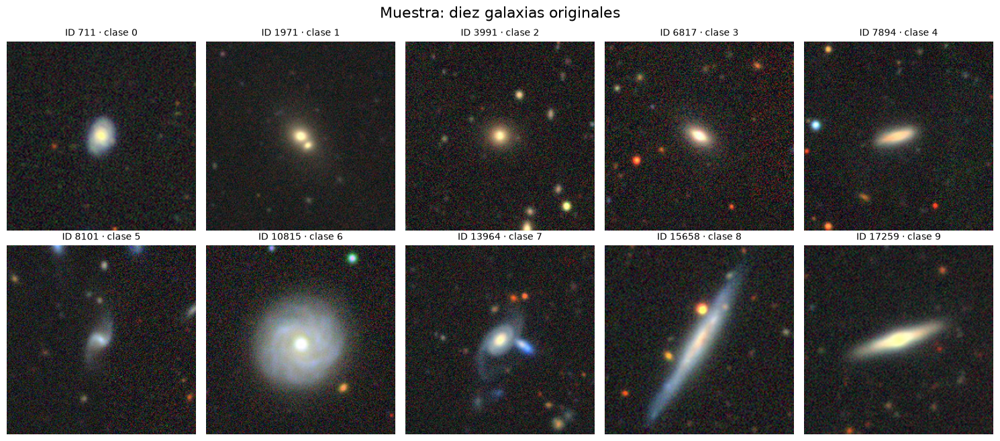

In [3]:
def mostrar_diez(lista, titulo, gris=False, etiquetas=False):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6.8))
    for ax, fila, imagen in zip(axes.flat, muestra.itertuples(), lista):
        ax.imshow(imagen, cmap='turbo' if etiquetas else 'gray' if gris else None,
                  **({'vmin': 0, 'vmax': 255} if gris and not etiquetas else {}))
        ax.set_title(f'ID {fila.image_id} · clase {fila.label}', fontsize=10)
        ax.axis('off')
    fig.suptitle(titulo, fontsize=16)
    fig.tight_layout()
    return fig

fig = mostrar_diez([imagenes[int(i)] for i in muestra.image_id], 'Muestra: diez galaxias originales')
fig.savefig(SALIDA / 'originales.png', dpi=140, bbox_inches='tight')
plt.show()

## 4. Código completo de split and merge
**Split:** subdividir en cuatro si la desviación estándar supera `tau` y los hijos alcanzan el tamaño mínimo. Un bloque mínimo puede seguir siendo heterogéneo.

**Merge:** fusionar regiones que comparten borde cuando la desviación de la unión es menor o igual a `tau`. Se actualizan estadísticas y vecinos, con una cola que prioriza la menor desviación.

**Primer plano:** conservar regiones cuya media supera la mediana del borde más `fondo_k` veces `max(1, 1.4826 × MAD)`. Es una decisión propia del proyecto y supone un perímetro representativo del fondo.

Es una variante de la familia descrita por Horowitz y Pavlidis, no una reproducción literal del algoritmo del artículo. La función siguiente es la misma del archivo `segmentacion.py`.

In [4]:
"""Segmentación split-and-merge con NumPy y OpenCV.

Los umbrales usan intensidades de 0 a 255. Los valores predeterminados son
puntos de partida que deben ajustarse con imágenes de validación.
"""

import heapq

import cv2
import numpy as np


def segmentar_split_merge(rgb, tau=10.0, min_size=4, fondo_k=3.0):
    """Devuelve (rgb_segmentada, mascara, etiquetas, estadisticas).

    Divide bloques heterogéneos en cuatro y fusiona regiones que comparten
    borde cuando la desviación estándar de su unión es <= tau. La fusión
    prioriza la unión con menor desviación y actualiza las adyacencias.

    La máscara conserva regiones cuya intensidad media supera la mediana
    del borde + fondo_k * sigma robusta del borde. Esta regla supone fondo
    oscuro en el perímetro; no identifica semánticamente la galaxia central.

    Args:
        rgb: Imagen uint8 de forma (alto, ancho, 3), en orden RGB.
        tau: Desviación estándar máxima para considerar homogénea una región.
        min_size: Tamaño mínimo de los hijos al dividir un bloque.
        fondo_k: Distancia al fondo, en unidades de sigma robusta.

    Returns:
        rgb_segmentada: RGB de entrada con fondo negro.
        mascara: uint8, con valores 0 y 255.
        etiquetas: int32, etiquetas consecutivas desde cero, incluido el fondo.
        estadisticas: Conteos y parámetros descriptivos de la segmentación.
    """
    rgb = np.asarray(rgb)
    if (rgb.ndim != 3 or rgb.shape[2] != 3 or rgb.dtype != np.uint8
            or min(rgb.shape[:2]) == 0):
        raise ValueError("rgb debe ser una imagen uint8 no vacía de forma (H, W, 3).")
    if not np.isfinite(tau) or tau < 0:
        raise ValueError("tau debe ser finito y >= 0.")
    if not isinstance(min_size, (int, np.integer)) or min_size < 1:
        raise ValueError("min_size debe ser un entero >= 1.")
    if not np.isfinite(fondo_k) or fondo_k < 0:
        raise ValueError("fondo_k debe ser finito y >= 0.")

    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    alto, ancho = gris.shape
    etiquetas = np.empty((alto, ancho), dtype=np.int32)
    cantidades, sumas, cuadrados = [], [], []

    def dividir(y0, y1, x0, x1):
        bloque = gris[y0:y1, x0:x1].astype(np.float64)
        puede_dividir = (y1 - y0 >= 2 * min_size
                         and x1 - x0 >= 2 * min_size)
        if puede_dividir and bloque.std() > tau:
            ym, xm = (y0 + y1) // 2, (x0 + x1) // 2
            dividir(y0, ym, x0, xm)
            dividir(y0, ym, xm, x1)
            dividir(ym, y1, x0, xm)
            dividir(ym, y1, xm, x1)
        else:
            etiqueta = len(cantidades)
            etiquetas[y0:y1, x0:x1] = etiqueta
            cantidades.append(bloque.size)
            sumas.append(float(bloque.sum()))
            cuadrados.append(float(np.square(bloque).sum()))

    dividir(0, alto, 0, ancho)
    n_split = len(cantidades)
    vecinos = [set() for _ in range(n_split)]

    # Adyacencia de cuatro vecinos, también entre hojas de distinto tamaño.
    for a, b in ((etiquetas[:, :-1], etiquetas[:, 1:]),
                 (etiquetas[:-1, :], etiquetas[1:, :])):
        diferentes = a != b
        pares = np.column_stack((a[diferentes], b[diferentes]))
        pares.sort(axis=1)
        for i, j in np.unique(pares, axis=0):
            vecinos[i].add(int(j))
            vecinos[j].add(int(i))

    padres = np.arange(n_split)
    versiones = np.zeros(n_split, dtype=np.int64)
    pendientes = []

    def desviacion_union(i, j):
        n = cantidades[i] + cantidades[j]
        media = (sumas[i] + sumas[j]) / n
        varianza = (cuadrados[i] + cuadrados[j]) / n - media * media
        return float(np.sqrt(max(0.0, varianza)))

    def proponer(i, j):
        i, j = min(i, j), max(i, j)
        desviacion = desviacion_union(i, j)
        if desviacion <= tau:
            heapq.heappush(pendientes, (desviacion, i, j,
                                       int(versiones[i]), int(versiones[j])))

    for i in range(n_split):
        for j in sorted(vecinos[i]):
            if i < j:
                proponer(i, j)

    while pendientes:
        _, i, j, vi, vj = heapq.heappop(pendientes)
        if (padres[i] != i or padres[j] != j
                or versiones[i] != vi or versiones[j] != vj
                or j not in vecinos[i]):
            continue

        # i absorbe j; las estadísticas permiten calcular la varianza exacta
        # de la unión, sin recorrer otra vez todos sus píxeles.
        padres[j] = i
        cantidades[i] += cantidades[j]
        sumas[i] += sumas[j]
        cuadrados[i] += cuadrados[j]
        versiones[i] += 1
        adyacentes = (vecinos[i] | vecinos[j]) - {i, j}
        for k in sorted(adyacentes):
            vecinos[k].discard(j)
            vecinos[k].add(i)
        vecinos[i] = adyacentes
        vecinos[j].clear()
        for k in sorted(adyacentes):
            proponer(i, k)

    def raiz(i):
        while padres[i] != i:
            padres[i] = padres[padres[i]]
            i = int(padres[i])
        return i

    raices = np.array([raiz(i) for i in range(n_split)])
    regiones, indices = np.unique(raices, return_inverse=True)
    etiquetas = indices[etiquetas].astype(np.int32)
    medias = np.array([sumas[i] / cantidades[i] for i in regiones])

    # Cada píxel del perímetro se cuenta una sola vez, incluso en imágenes
    # de una sola fila o columna.
    borde = np.zeros(gris.shape, dtype=bool)
    borde[[0, -1], :] = True
    borde[:, [0, -1]] = True
    valores_borde = gris[borde].astype(np.float64)
    fondo = float(np.median(valores_borde))
    mad = float(np.median(np.abs(valores_borde - fondo)))
    sigma_fondo = max(1.0, 1.4826 * mad)
    umbral_fondo = fondo + fondo_k * sigma_fondo
    mascara = (medias[etiquetas] > umbral_fondo).astype(np.uint8) * 255
    segmentada = cv2.bitwise_and(rgb, rgb, mask=mascara)
    n_componentes, _ = cv2.connectedComponents(mascara, connectivity=8)

    stats = {
        "otsu_threshold": np.nan,
        "segmented_pct": float(100 * np.count_nonzero(mascara) / mascara.size),
        "num_regions": int(n_componentes - 1),
        "split_regions": n_split,
        "merged_regions": int(len(regiones)),
        "foreground_regions": int(np.count_nonzero(medias > umbral_fondo)),
        "background_threshold": umbral_fondo,
    }
    return segmentada, mascara, etiquetas, stats

## 5. Gaussian, CLAHE, Otsu y los siete tratamientos
Gaussian: kernel 5 × 5 y sigma 1. CLAHE: canal L en LAB, `clipLimit=2`, cuadrícula 8 × 8. Otsu calcula un umbral global por imagen. En ambos métodos de segmentación se aplica la máscara sobre la RGB preprocesada.

La función devuelve RGB, máscara, mapa de regiones y estadísticas. Las máscaras y los mapas solo existen en los tratamientos de segmentación que corresponden.

In [5]:
def aplicar_tratamiento_demo(rgb, tratamiento):
    rgb = np.asarray(rgb, dtype=np.uint8)
    stats = {'otsu_threshold': np.nan, 'segmented_pct': np.nan, 'num_regions': np.nan}
    if tratamiento == 'original':
        return rgb.copy(), None, None, stats
    if tratamiento in ['gaussian', 'gaussian_otsu', 'gaussian_split_merge']:
        procesada = cv2.GaussianBlur(rgb, (5, 5), sigmaX=1)
    elif tratamiento in ['clahe', 'clahe_otsu', 'clahe_split_merge']:
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
        procesada = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)
    else:
        raise ValueError(tratamiento)
    if tratamiento.endswith('_split_merge'):
        return segmentar_split_merge(procesada, **PARAMETROS)
    if tratamiento.endswith('_otsu'):
        gris = cv2.cvtColor(procesada, cv2.COLOR_RGB2GRAY)
        umbral, mascara = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        final = cv2.bitwise_and(procesada, procesada, mask=mascara)
        n, _ = cv2.connectedComponents(mascara, connectivity=8)
        stats = {'otsu_threshold': float(umbral),
                 'segmented_pct': float(100 * np.count_nonzero(mascara) / mascara.size),
                 'num_regions': int(n - 1)}
        return final, mascara, None, stats
    return procesada, None, None, stats

## 6. Ejecutar los siete tratamientos: diez imágenes cada uno
Aquí se calculan realmente las 70 imágenes. Se compara una huella de cada RGB con la implementación original para identificar cualquier cambio de parámetros o diferencias entre versiones. Una discrepancia impide asociar silenciosamente las predicciones guardadas con una entrada diferente.

In [6]:
resultados = {}; registros = []
for tratamiento in TRATAMIENTOS:
    for fila in muestra.itertuples():
        image_id = int(fila.image_id)
        inicio = time.perf_counter()
        final, mascara, regiones, stats = aplicar_tratamiento_demo(imagenes[image_id], tratamiento)
        duracion = time.perf_counter() - inicio
        coincide = hashlib.sha256(final.tobytes()).hexdigest() == referencias_rgb[f'{image_id}/{tratamiento}']
        resultados[(tratamiento, image_id)] = {'rgb': final, 'mascara': mascara, 'regiones': regiones}
        registros.append({'treatment': tratamiento, 'image_id': image_id, 'label': int(fila.label),
                          'preprocessing_demo_s': duracion, 'coincide_rgb_referencia': coincide, **stats})
estadisticas_demo = pd.DataFrame(registros)
assert len(resultados) == len(estadisticas_demo) == 70
assert (estadisticas_demo.groupby('treatment').size() == 10).all()
print('Calculadas 70 imágenes: 10 por cada uno de los 7 tratamientos.')
print('RGB iguales a la implementación original:', int(estadisticas_demo.coincide_rgb_referencia.sum()), '/ 70')
if not estadisticas_demo.coincide_rgb_referencia.all():
    print('AVISO: hay RGB distintas. Las predicciones guardadas describen la configuración original, no esas entradas nuevas.')

Calculadas 70 imágenes: 10 por cada uno de los 7 tratamientos.
RGB iguales a la implementación original: 70 / 70


## 7. Diez ejemplos por cada tratamiento
Cada figura muestra las mismas diez galaxias. Los PNG también se guardan para la presentación y el ZIP.

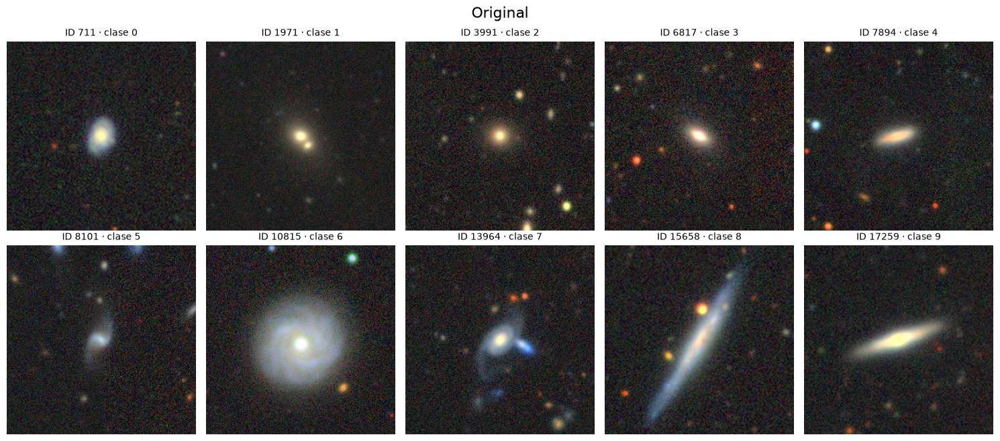

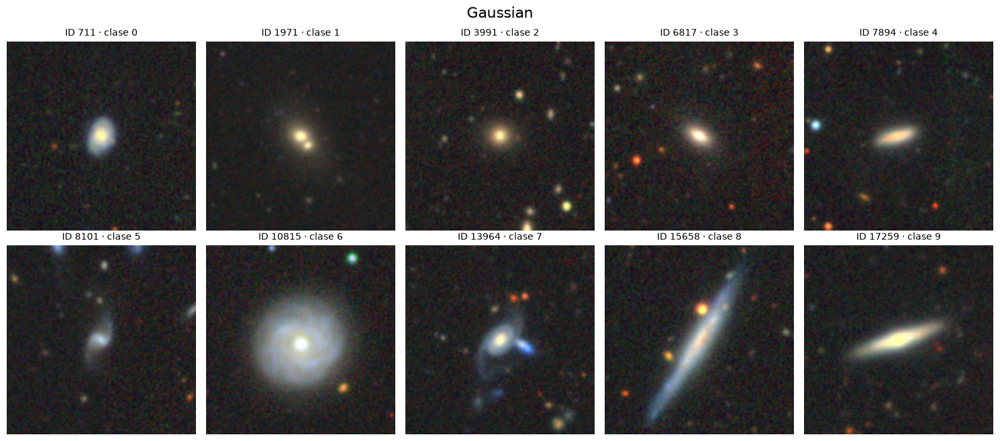

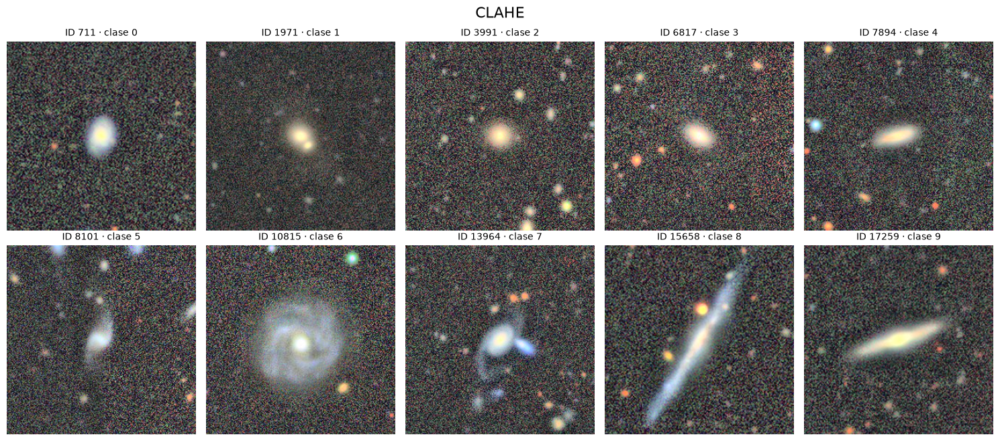

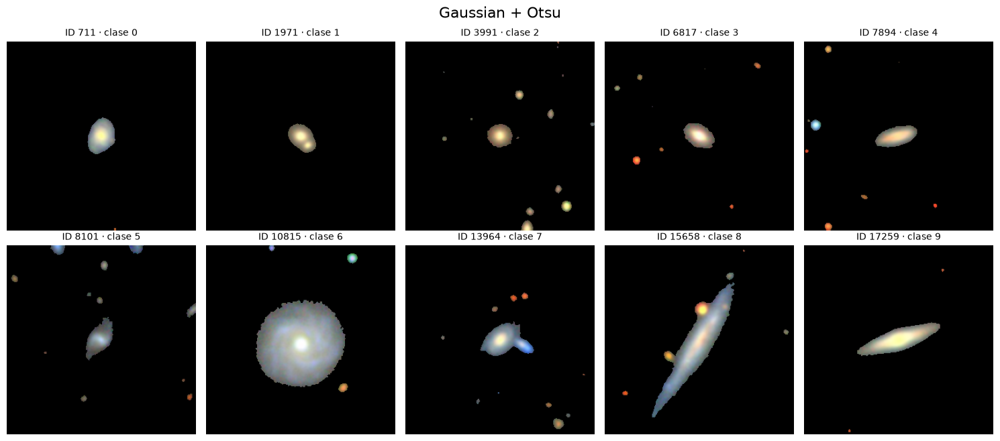

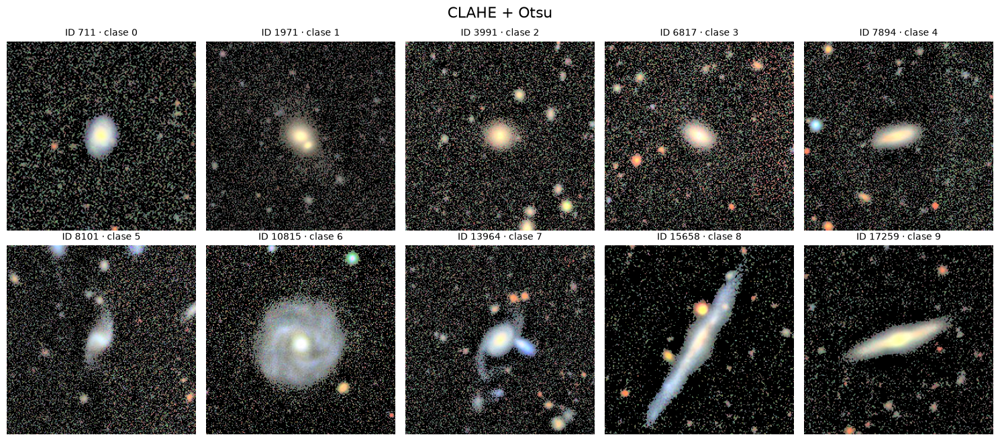

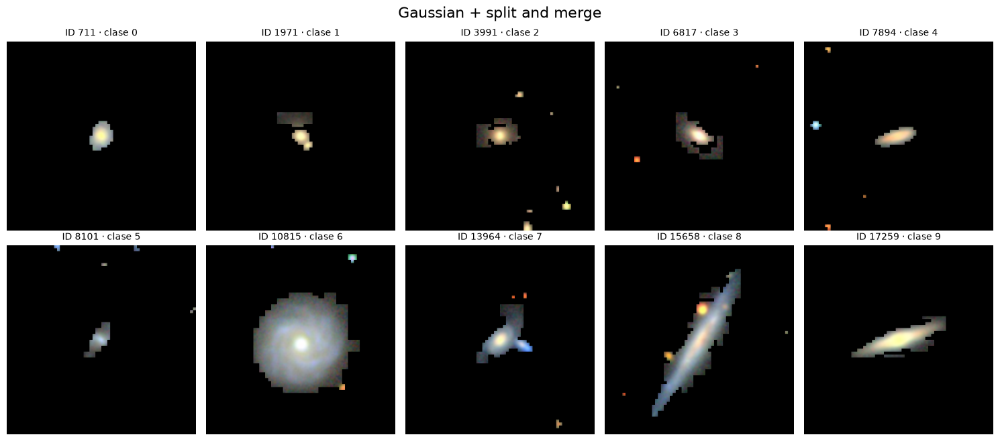

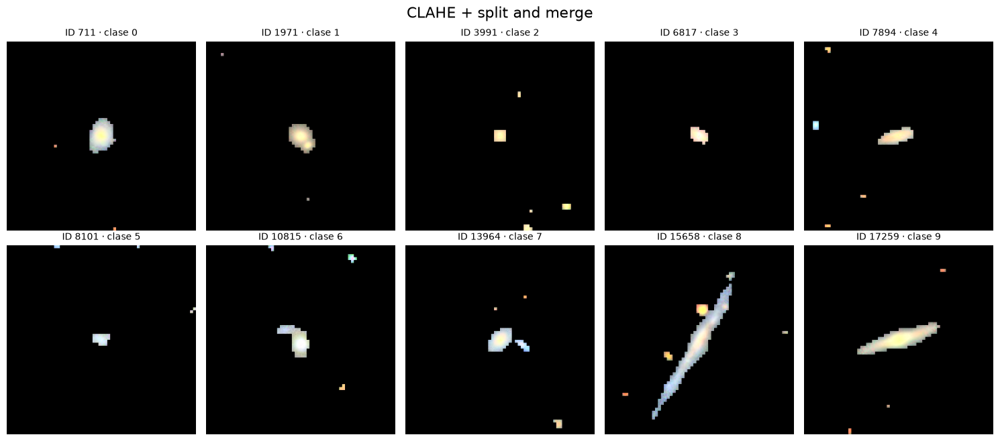

In [7]:
for tratamiento, nombre in zip(TRATAMIENTOS, NOMBRES):
    lista = [resultados[(tratamiento, int(i))]['rgb'] for i in muestra.image_id]
    fig = mostrar_diez(lista, nombre)
    fig.savefig(SALIDA / f'comparacion_{tratamiento}.png', dpi=140, bbox_inches='tight')
    plt.show()

## 8. Máscaras y regiones de segmentación
Se muestran diez máscaras para cada uno de los cuatro tratamientos segmentados. Los colores del mapa de regiones identifican particiones y no clases morfológicas. Los conteos de regiones fusionadas y componentes conectados de la máscara describen cosas distintas.

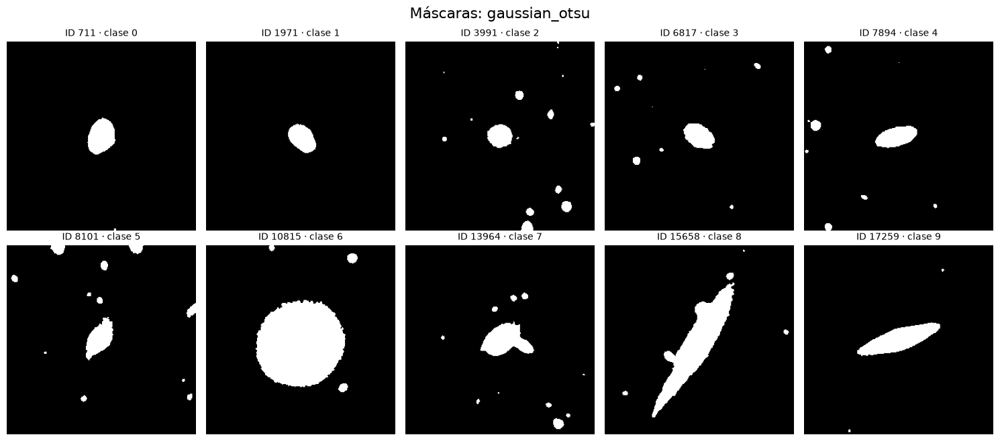

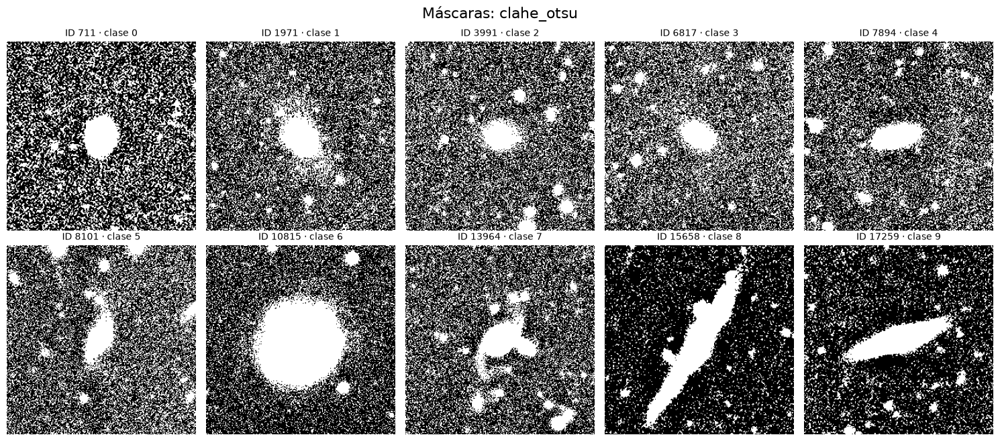

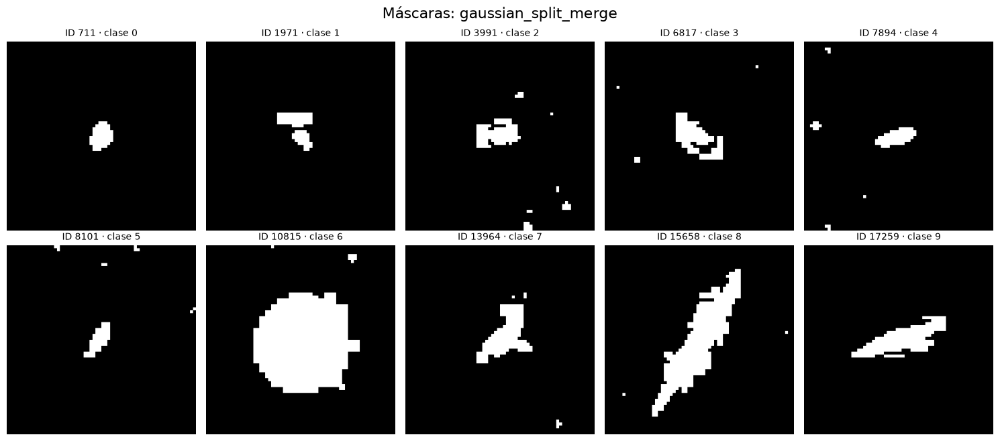

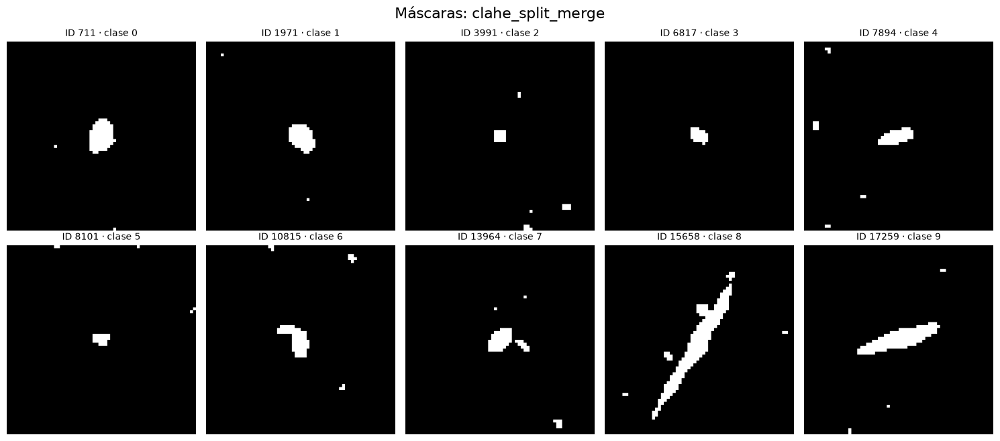

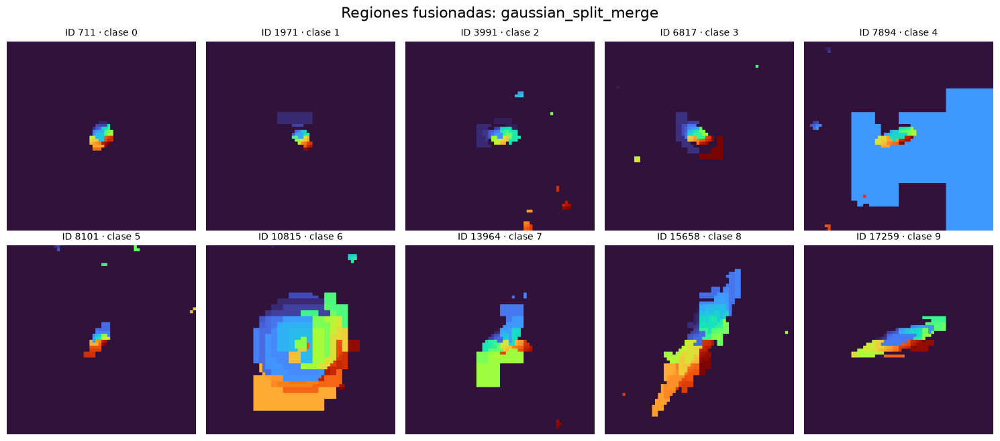

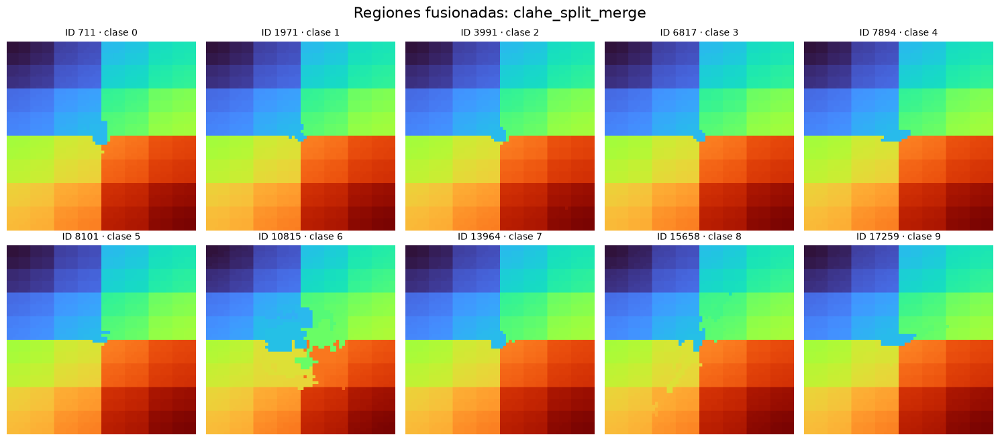

,segmented_pct,num_regions,merged_regions
treatment,,,
clahe,NaN,NaN,NaN
clahe_otsu,36.110,1861.6,NaN
clahe_split_merge,2.012,3.9,3997.7
gaussian,NaN,NaN,NaN
gaussian_otsu,4.802,7.1,NaN
gaussian_split_merge,5.811,3.5,70.1
original,NaN,NaN,NaN


In [8]:
for tratamiento in [t for t in TRATAMIENTOS if t.endswith('_otsu') or t.endswith('_split_merge')]:
    lista = [resultados[(tratamiento, int(i))]['mascara'] for i in muestra.image_id]
    fig = mostrar_diez(lista, f'Máscaras: {tratamiento}', gris=True)
    fig.savefig(SALIDA / f'mascaras_{tratamiento}.png', dpi=140, bbox_inches='tight')
    plt.show()
for tratamiento in ['gaussian_split_merge', 'clahe_split_merge']:
    lista = [resultados[(tratamiento, int(i))]['regiones'] for i in muestra.image_id]
    fig = mostrar_diez(lista, f'Regiones fusionadas: {tratamiento}', etiquetas=True)
    fig.savefig(SALIDA / f'regiones_{tratamiento}.png', dpi=140, bbox_inches='tight')
    plt.show()
display(estadisticas_demo.groupby('treatment')[['segmented_pct', 'num_regions', 'merged_regions']].mean().round(3))

## 9. Histograma y umbral de Otsu
Elegimos la primera imagen de la muestra para comparar el efecto de Gaussian y CLAHE sobre el histograma. Los umbrales son de esta imagen, no del conjunto entero.

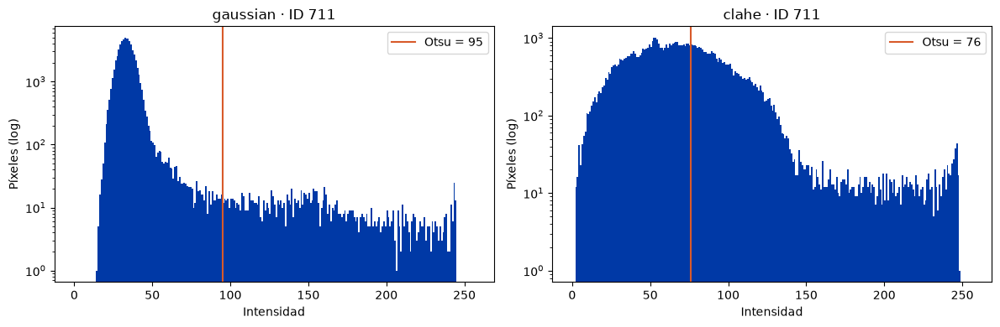

In [9]:
ejemplo_id = int(muestra.iloc[0].image_id)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, base in zip(axes, ['gaussian', 'clahe']):
    gris = cv2.cvtColor(resultados[(base, ejemplo_id)]['rgb'], cv2.COLOR_RGB2GRAY)
    umbral = float(estadisticas_demo.loc[(estadisticas_demo.treatment == base + '_otsu') &
                    (estadisticas_demo.image_id == ejemplo_id), 'otsu_threshold'].iloc[0])
    ax.hist(gris.ravel(), bins=256, range=(0, 256), color='#0039a6')
    ax.axvline(umbral, color='#d85a2a', label=f'Otsu = {umbral:.0f}')
    ax.set_yscale('log'); ax.set_xlabel('Intensidad'); ax.set_ylabel('Píxeles (log)')
    ax.set_title(f'{base} · ID {ejemplo_id}'); ax.legend()
fig.tight_layout(); fig.savefig(SALIDA / 'histogramas_otsu.png', dpi=140)
plt.show()

## 10. Qwen: prompt y predicciones guardadas
El modelo del experimento es Qwen3-VL-4B-Instruct, con cuantización NF4 de 4 bits y generación determinista. Las respuestas siguientes se leen de los CSV originales. No se están generando nuevas respuestas en esta celda.

In [10]:
PROMPT = 'Classify the morphology of the main galaxy\nnear the center of the image.\n\nChoose exactly one category:\n\n0: Disturbed\n1: Merging\n2: Round Smooth\n3: In-between Smooth\n4: Cigar-shaped Smooth\n5: Barred Spiral\n6: Unbarred Tight Spiral\n7: Unbarred Loose Spiral\n8: Edge-on without Bulge\n9: Edge-on with Bulge\n\nReturn ONLY one digit from 0 to 9.\nDo not explain.'

print(PROMPT)
filas_pred = []
for tratamiento in TRATAMIENTOS:
    seleccion = predicciones_guardadas[tratamiento].merge(muestra, on=['image_id', 'label'], how='inner')
    seleccion['treatment'] = tratamiento
    filas_pred.append(seleccion)
predicciones_muestra = pd.concat(filas_pred, ignore_index=True).merge(
    estadisticas_demo[['treatment', 'image_id', 'coincide_rgb_referencia']], on=['treatment', 'image_id'], validate='one_to_one')
assert len(predicciones_muestra) == 70
display(predicciones_muestra.pivot(index=['image_id', 'label'], columns='treatment', values='prediction'))

Classify the morphology of the main galaxy
near the center of the image.

Choose exactly one category:

0: Disturbed
1: Merging
2: Round Smooth
3: In-between Smooth
4: Cigar-shaped Smooth
5: Barred Spiral
6: Unbarred Tight Spiral
7: Unbarred Loose Spiral
8: Edge-on without Bulge
9: Edge-on with Bulge

Return ONLY one digit from 0 to 9.
Do not explain.


,treatment,clahe,clahe_otsu,clahe_split_merge,gaussian,gaussian_otsu,gaussian_split_merge,original
image_id,label,,,,,,,
711,0,2,2,2,2,2,2,2
1971,1,2,2,2,2,2,2,2
3991,2,2,2,2,2,2,2,2
6817,3,2,2,2,2,2,5,2
7894,4,9,9,2,9,4,4,4
8101,5,2,2,2,2,2,2,2
10815,6,5,5,2,5,5,5,5
13964,7,1,1,2,1,1,5,1
15658,8,8,4,4,8,4,4,4


## 11. Métricas de la muestra y del experimento completo
Calculamos accuracy y F1 sobre las **predicciones históricas de las diez imágenes**, con diez etiquetas explícitas. Esta muestra pequeña sirve para explicar errores, sin sustituir la evaluación de las 1,000 imágenes. Las matrices de referencia tampoco se infieren de las imágenes de la demo.

Accuracy y F1 miden clasificación. Sin máscaras de referencia no corresponde reportar IoU ni Dice de segmentación.

MUESTRA: 10 imágenes por tratamiento, predicciones guardadas
EXPERIMENTO: 1,000 imágenes por tratamiento, predicciones guardadas


,treatment,n,accuracy,precision_macro,recall_macro,f1_macro
0,clahe,10,0.2,0.0700,0.2,0.1000
1,clahe_otsu,10,0.1,0.0200,0.1,0.0333
2,clahe_split_merge,10,0.1,0.0125,0.1,0.0222
3,gaussian,10,0.2,0.0700,0.2,0.1000
4,gaussian_otsu,10,0.3,0.1700,0.3,0.2000
5,gaussian_split_merge,10,0.2,0.0583,0.2,0.0900
6,original,10,0.3,0.1700,0.3,0.2000


,treatment,n,accuracy,precision_macro,recall_macro,f1_macro
4,clahe_otsu,1000,0.313,0.3439,0.313,0.2472
2,clahe,1000,0.310,0.2515,0.310,0.2387
1,gaussian,1000,0.286,0.2857,0.286,0.2224
0,original,1000,0.282,0.2417,0.282,0.2202
3,gaussian_otsu,1000,0.230,0.2288,0.230,0.1698
5,gaussian_split_merge,1000,0.218,0.2020,0.218,0.1565
6,clahe_split_merge,1000,0.162,0.1595,0.162,0.0926


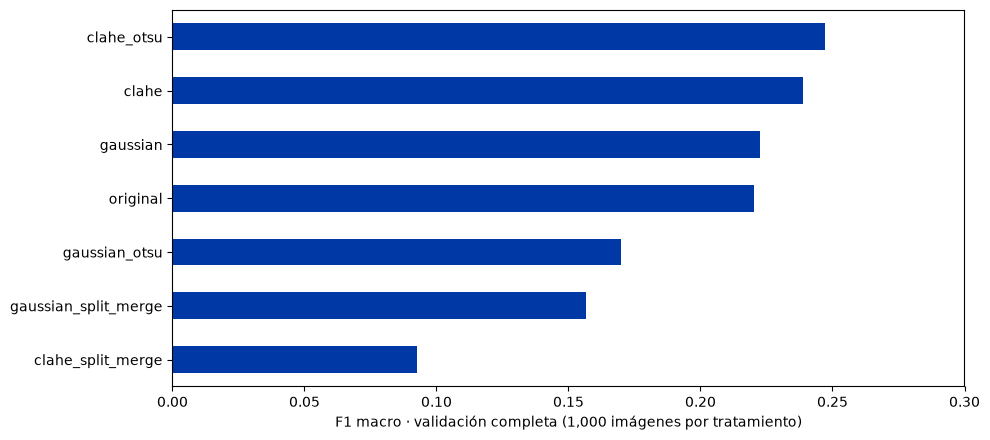

In [11]:
def resumir_predicciones(df):
    precision, recall, f1, _ = precision_recall_fscore_support(
        df.label, df.prediction, labels=list(range(10)), average=None, zero_division=0)
    return {'n': len(df), 'accuracy': accuracy_score(df.label, df.prediction),
            'precision_macro': precision.mean(), 'recall_macro': recall.mean(), 'f1_macro': f1.mean()}

tabla_muestra = pd.DataFrame([{'treatment': t, **resumir_predicciones(df)}
    for t, df in predicciones_muestra.groupby('treatment')])
tabla_completa = pd.DataFrame([{'treatment': t, 'n': m['total_inferences'],
    **{k: m[k] for k in ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']}}
    for t, m in metricas_guardadas.items()])
for t in TRATAMIENTOS:
    recalculadas = resumir_predicciones(predicciones_guardadas[t])
    for k in ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']:
        assert np.isclose(recalculadas[k], metricas_guardadas[t][k])
print('MUESTRA: 10 imágenes por tratamiento, predicciones guardadas')
display(tabla_muestra.round(4))
print('EXPERIMENTO: 1,000 imágenes por tratamiento, predicciones guardadas')
display(tabla_completa.sort_values('f1_macro', ascending=False).round(4))
ax = tabla_completa.sort_values('f1_macro').plot.barh(x='treatment', y='f1_macro', legend=False,
    figsize=(10, 4.5), color='#0039a6', xlim=(0, .30))
ax.set_xlabel('F1 macro · validación completa (1,000 imágenes por tratamiento)'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(SALIDA / 'f1_validacion_completa.png', dpi=140); plt.show()

## 12. Matrices de confusión y errores por clase
Estas matrices corresponden al **experimento completo**. Comparan el mejor F1 macro con CLAHE + split and merge. Todas las filas suman 100. La tabla de F1 por clase ayuda a reconocer dificultades que las métricas globales ocultan.

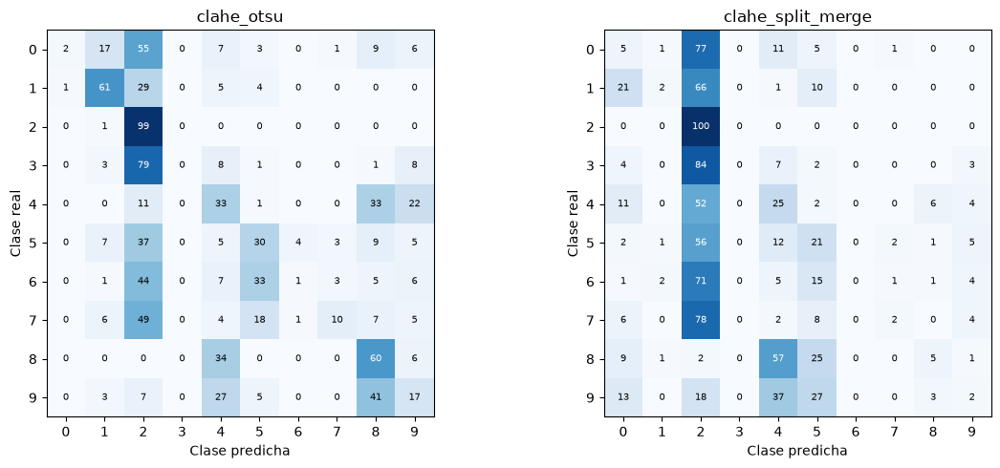

,original,gaussian,clahe,gaussian_otsu,clahe_otsu,gaussian_split_merge,clahe_split_merge
Disturbed,0.000,0.000,0.000,0.018,0.039,0.060,0.058
Merging,0.510,0.510,0.628,0.447,0.613,0.361,0.037
Round Smooth,0.321,0.336,0.388,0.332,0.388,0.352,0.284
In-between Smooth,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Cigar-shaped Smooth,0.296,0.249,0.290,0.275,0.287,0.174,0.195
Barred Spiral,0.289,0.338,0.297,0.226,0.308,0.275,0.195
Unbarred Tight Spiral,0.000,0.037,0.019,0.000,0.019,0.000,0.000
Unbarred Loose Spiral,0.037,0.038,0.102,0.000,0.171,0.000,0.038
Edge-on without Bulge,0.579,0.563,0.521,0.315,0.453,0.239,0.086
Edge-on with Bulge,0.171,0.153,0.143,0.084,0.194,0.104,0.033


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, t in zip(axes, ['clahe_otsu', 'clahe_split_merge']):
    df = predicciones_guardadas[t]
    cm = confusion_matrix(df.label, df.prediction, labels=list(range(10)))
    assert (cm.sum(axis=1) == 100).all()
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=100)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > 50 else 'black')
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel('Clase predicha'); ax.set_ylabel('Clase real'); ax.set_title(t)
fig.tight_layout(); fig.savefig(SALIDA / 'matrices_validacion_completa.png', dpi=140); plt.show()
f1_clases = pd.DataFrame({t: [metricas_guardadas[t][f'f1_class_{i}'] for i in range(10)] for t in TRATAMIENTOS}, index=CLASES)
display(f1_clases.round(3))

## 13. Código de inferencia de `evaluar_qwen.py`
La función siguiente muestra cómo el experimento prepara la imagen, envía el prompt, genera la respuesta y valida el dígito. Se incluye el código real para explicarlo. Definir una función no ejecuta el modelo.

La celda opcional posterior descarga el modelo y ejecuta 70 inferencias si se activa; necesita GPU, memoria y tiempo adicionales. Es una ejecución de la muestra, no una repetición de las 7,000 clasificaciones originales.

In [13]:
def clasificar(rgb, processor, model, max_tokens):
    imagen = Image.fromarray(rgb).convert("RGB")

    mensajes = [{
        "role": "user",
        "content": [
            {"type": "image", "image": imagen},
            {"type": "text", "text": PROMPT},
        ],
    }]

    inputs = processor.apply_chat_template(
        mensajes,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            use_cache=True,
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latencia = time.perf_counter() - inicio

    tokens_nuevos = output[0][
        inputs["input_ids"].shape[-1]:
    ]

    respuesta = processor.decode(
        tokens_nuevos,
        skip_special_tokens=True
    ).strip()

    valido = bool(re.fullmatch(r"[0-9]", respuesta))
    prediccion = int(respuesta) if valido else -1

    return prediccion, respuesta, valido, latencia

In [14]:
EJECUTAR_QWEN = False  # Cambiar a True solo si se quiere inferencia nueva en GPU.

if EJECUTAR_QWEN:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'transformers', 'accelerate', 'bitsandbytes'])
    import torch
    from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration
    if not torch.cuda.is_available():
        raise RuntimeError('Selecciona una GPU en el entorno de ejecución de Colab.')
    torch.manual_seed(42)
    MODEL_ID = 'Qwen/Qwen3-VL-4B-Instruct'
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model = Qwen3VLForConditionalGeneration.from_pretrained(MODEL_ID, device_map='auto',
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
            bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True))
    model.eval()
    nuevas = []
    for t in TRATAMIENTOS:
        for fila in muestra.itertuples():
            pred, respuesta, valido, latencia = clasificar(resultados[(t, int(fila.image_id))]['rgb'], processor, model, 16)
            nuevas.append({'treatment': t, 'image_id': int(fila.image_id), 'label': int(fila.label),
                           'prediction': pred, 'raw_response': respuesta, 'valid': valido, 'latency_s': latencia})
    predicciones_nuevas = pd.DataFrame(nuevas)
    predicciones_nuevas.to_csv(SALIDA / 'predicciones_qwen_nuevas_70.csv', index=False)
    display(pd.DataFrame([{'treatment': t, **resumir_predicciones(df)} for t, df in predicciones_nuevas.groupby('treatment')]))
else:
    print('Inferencia nueva desactivada. La demo consulta las predicciones del experimento ya terminado.')

Inferencia nueva desactivada. La demo consulta las predicciones del experimento ya terminado.


## 14. MLflow: consultar los runs originales y registro opcional
La tabla muestra los identificadores originales. La base SQLite del equipo no se conecta automáticamente con Colab. Para consultar esa interfaz en el equipo original: `mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000`.

El registro opcional siguiente crea **otro experimento**, llamado `Galaxy10_Demo_10x7`, en una base dentro de la salida de la demo. Etiqueta expresamente si las predicciones son guardadas o nuevas y no modifica el experimento original. Esa nueva base se incluye en la exportación.

In [15]:
display(pd.DataFrame([{'treatment': t, 'run_id_original': run_ids[t],
    'n_original': 1000, 'n_muestra': 10} for t in TRATAMIENTOS]))

REGISTRAR_MLFLOW = False
if REGISTRAR_MLFLOW:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mlflow'])
    import mlflow
    mlflow.set_tracking_uri('sqlite:///' + (SALIDA / 'mlflow_demo.db').resolve().as_posix())
    mlflow.set_experiment('Galaxy10_Demo_10x7')
    origen = 'nuevas' if EJECUTAR_QWEN else 'guardadas'
    datos_log = predicciones_nuevas if EJECUTAR_QWEN else predicciones_muestra
    for t in TRATAMIENTOS:
        df = datos_log[datos_log.treatment == t]
        with mlflow.start_run(run_name=f'{t}_demo_10'):
            mlflow.log_params({'treatment': t, 'sample_size': 10, 'prediction_source': origen, **PARAMETROS})
            mlflow.set_tags({'scope': 'demo', 'original_run_id': run_ids[t]})
            mlflow.log_metrics(resumir_predicciones(df))
            mlflow.log_text(df.to_csv(index=False), 'predictions.csv')
            mlflow.log_text(muestra.to_csv(index=False), 'sample.csv')
    print('Guardada una nueva base de MLflow para la demo en', SALIDA / 'mlflow_demo.db')
else:
    print('Registro adicional desactivado; los runs originales se conservan como referencia.')

Registro adicional desactivado; los runs originales se conservan como referencia.


,treatment,run_id_original,n_original,n_muestra
0,original,f9c63eac92444deb857068c281dd1dff,1000,10
1,gaussian,d5973d914e2d45368ac0bd030b9d9ba0,1000,10
2,clahe,0a7731d4ea36433b9cda881486364013,1000,10
3,gaussian_otsu,f74b08f086fc4f6caa85908b6905cd27,1000,10
4,clahe_otsu,cedbcd522a0a42ef8f8a02451f677d18,1000,10
5,gaussian_split_merge,3e3eb537112a4de0bde7704ef1610f3c,1000,10
6,clahe_split_merge,6711c4f32c884d229eb2924c3e455206,1000,10


## 15. Exportar las 70 imágenes, las máscaras, mapas y tablas
Este bloque cumple la función del exportador de segmentación para la muestra del tutorial. Las estadísticas de tiempos nuevas corresponden a esta máquina; los tiempos guardados de Qwen pertenecen al experimento original.

Se exportan originales, 70 RGB procesadas, 40 máscaras y 20 mapas de regiones, además de mosaicos, tablas, configuraciones y predicciones completas para trazabilidad. El ZIP no necesita el dataset HDF5 ni los pesos del modelo.

In [16]:
muestra.to_csv(SALIDA / 'muestra_10.csv', index=False)
estadisticas_demo.to_csv(SALIDA / 'estadisticas_segmentacion_70.csv', index=False)
predicciones_muestra.to_csv(SALIDA / 'predicciones_guardadas_muestra_70.csv', index=False)
tabla_muestra.to_csv(SALIDA / 'metricas_muestra_10.csv', index=False)
tabla_completa.to_csv(SALIDA / 'metricas_validacion_1000.csv', index=False)
for fila in muestra.itertuples():
    Image.fromarray(imagenes[int(fila.image_id)]).save(SALIDA / f'original_{fila.image_id}.png')
for (t, image_id), contenido in resultados.items():
    carpeta = SALIDA / t; carpeta.mkdir(exist_ok=True)
    Image.fromarray(contenido['rgb']).save(carpeta / f'{image_id}_rgb.png')
    if contenido['mascara'] is not None:
        Image.fromarray(contenido['mascara']).save(carpeta / f'{image_id}_mascara.png')
    if contenido['regiones'] is not None:
        np.save(carpeta / f'{image_id}_regiones.npy', contenido['regiones'])
for t in TRATAMIENTOS:
    predicciones_guardadas[t].to_csv(SALIDA / t / 'predicciones_originales_1000.csv', index=False)
(SALIDA / 'configuraciones_experimento.json').write_text(json.dumps(configuraciones, indent=2), encoding='utf-8')
(SALIDA / 'config_demo.json').write_text(json.dumps({'sample_size': 10, 'treatments': TRATAMIENTOS,
    'parametros_split_merge': PARAMETROS, 'opencv': cv2.__version__, 'numpy': np.__version__,
    'prediction_source_default': 'guardadas', 'original_run_ids': run_ids}, indent=2), encoding='utf-8')
print('Archivos exportados en:', SALIDA.resolve())

Archivos exportados en: C:\Users\USER\OneDrive - Instituto Tecnologico y de Estudios Superiores de Monterrey\Vision computacional\Proyecto final\tmp\tutorial_validation\salida_demo_galaxy10


## 16. Interpretación y límites
- Comparar muestras de diez imágenes ayuda a explicar el código. Los resultados experimentales reportados corresponden a 1,000 imágenes por tratamiento.
- CLAHE + Otsu obtuvo el mejor F1 macro de esa validación. Las variantes evaluadas de split and merge redujeron el desempeño.
- La pérdida de estructuras tenues es una hipótesis visual, no una causa demostrada. La evaluación combina particionado y regla de primer plano.
- El número de píxeles conservados no mide por sí solo calidad de segmentación. No tenemos máscaras de referencia para IoU/Dice.
- Las respuestas de Qwen guardadas solo corresponden a los parámetros y RGB originales. Las celdas opcionales permiten evaluar nuevas entradas sin confundirlas con los resultados históricos.

## 17. Contribuciones del equipo
Completar con los nombres y aportaciones reales antes de entregar. No inventar participantes.

| Integrante | Contribución específica |
|---|---|
| Pendiente de completar | Investigación y análisis del artículo |
| Pendiente de completar | Implementación y explicación del algoritmo |
| Pendiente de completar | Evaluación, MLflow y análisis de resultados |
| Pendiente de completar | Visualizaciones y preparación del tutorial |

Reemplazar o ajustar las filas al número real de integrantes.

## 18. Referencias
1. Horowitz, S. L., & Pavlidis, T. (1976). *Picture Segmentation by a Tree Traversal Algorithm*. Journal of the ACM, 23(2), 368-388. https://doi.org/10.1145/321941.321956
2. Fu, G., Zhao, H., Li, C., & Shi, L. (2013). *Segmentation for High-Resolution Optical Remote Sensing Imagery Using Improved Quadtree and Region Adjacency Graph Technique*. Remote Sensing, 5(7), 3259-3279. https://doi.org/10.3390/rs5073259
3. Otsu, N. (1979). *A Threshold Selection Method from Gray-Level Histograms*. IEEE Transactions on Systems, Man, and Cybernetics, 9(1), 62-66. https://doi.org/10.1109/TSMC.1979.4310076
4. Leung, W. H., & Bovy, J. (2024). *Galaxy10 DECaLS* [Dataset]. https://doi.org/10.5281/zenodo.10845026
5. OpenCV. *Image Thresholding*. https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html

Fuentes locales incluidas: `segmentacion.py`, función `clasificar` de `evaluar_qwen.py`, CSV de validación y los archivos de resultados de los siete tratamientos.

## 19. Descargar el ZIP de la demo
La descarga automática es opcional. El ZIP se crea en el directorio actual y también puede descargarse desde el panel de archivos de Colab.

In [17]:
import shutil
zip_demo = Path(shutil.make_archive('Demo_Galaxy10_10_por_tratamiento', 'zip', root_dir=SALIDA))
print('ZIP creado:', zip_demo.resolve())
DESCARGAR_EN_COLAB = False
if DESCARGAR_EN_COLAB:
    from google.colab import files
    files.download(str(zip_demo))

ZIP creado: C:\Users\USER\OneDrive - Instituto Tecnologico y de Estudios Superiores de Monterrey\Vision computacional\Proyecto final\tmp\tutorial_validation\Demo_Galaxy10_10_por_tratamiento.zip
